In [1]:
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA

sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_mouse import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
dims = 3

file_ids = list(range(0, 8+1))
# file_ids = [2]	# paper
plot_id = 2

In [4]:
# read
path = os.path.join(read_utils.get_data_path(), '6163622/sessions')
(file_ids, filenames,
 traces,
 continuous_behaviors,
 motion_pcs,
 motion_masks) = read_utils.get_datas(path, read_ids,
									  with_whisking=True)

# clear nan values
for i in range(len(file_ids)):
	# mask = motion_pcs[i][0].notna().all(axis=1)
	mask = continuous_behaviors[i].notna().all(axis=1)

	traces[i] = traces[i][mask]
	motion_pcs[i][0] = motion_pcs[i][0][mask]
	motion_pcs[i][1] = motion_pcs[i][1][mask]
	continuous_behaviors[i] = continuous_behaviors[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty or type(label) is not str else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

In [5]:
# prep

def reconstruct_calcium(spikes, fs, decay=2.0):
	dt = 1.0 / fs
	gamma = np.exp(-dt / decay)
	trace = np.zeros(spikes.shape, dtype=np.float32)
	for t in range(1, spikes.shape[0]):
		trace[t, :] = gamma * trace[t-1, :] + spikes[t, :]
	return trace

sampling_rates = [read_utils.get_sampling_rate(os.path.join(path, filenames[file_ids.index(file_id)])) for file_id in file_ids]

traces = [pd.DataFrame(reconstruct_calcium(trace.values, fs=sr), columns=trace.columns) for trace, sr in zip(traces, sampling_rates)]

behaviors = [mpc[0] for mpc in motion_pcs]

classes = [
	pd.DataFrame(cb[['running_speed']].values > np.quantile(cb[['running_speed']].values, 0.05), columns=['run'])
	for cb in continuous_behaviors
]

In [6]:
plot_idx = file_ids.index(plot_id)

In [7]:
(modes_manifold,
 recos_manifold,
 loads_pca_man,
 vars_expl_mans) = train_utils.get_manifolds_pca(traces, zscore=False,
												 n_pc=dims)

In [8]:
save = False

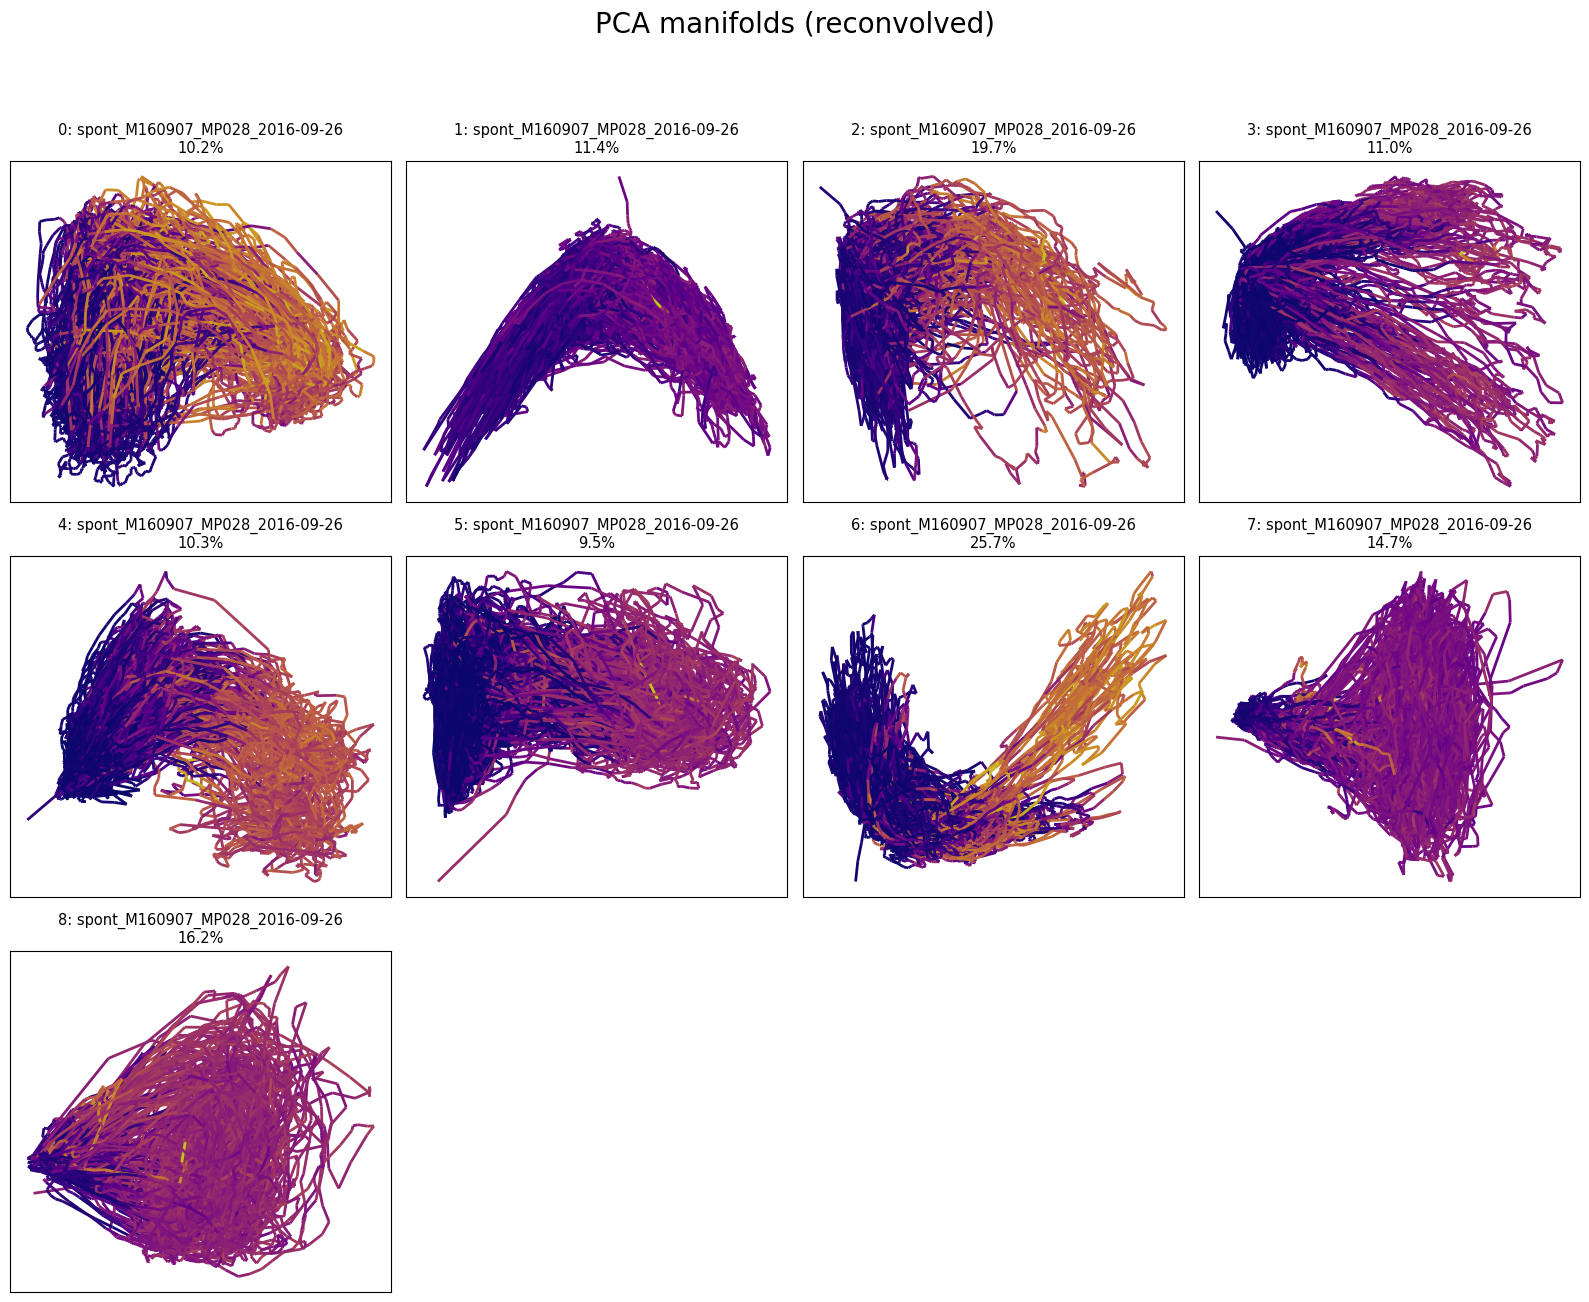

14.3%


In [9]:
plot_utils.plot_manifolds_gradient([f'{str(file_id)}: {filenames[plot_idx]}' for file_id in file_ids],
						  modes_manifold, [cb[['whisking']] for cb in continuous_behaviors],
						  [vx[:2] for vx in vars_expl_mans], None,
						  title='PCA manifolds (reconvolved)', top_space=1,
						  save_path=f'../../out/plots/manifolds/{dims}-dim-PCA' if save else None)

In [10]:
# plot_utils.plot_manifolds_3d_sep([f'{str(file_id)}: {filenames[plot_idx]}' for file_id in file_ids],
# 								 modes_manifold, None,
# 								 [vx[:3] for vx in vars_expl_mans], None,
# 								  titles=['PCA manifolds'] * len(file_ids), top_space=1, animate=True,
# 								 save_path=f'../../out/plots/manifolds/{dims}-dim-PCA_3d' if save else None)

In [15]:
for i, trace in enumerate(traces):
	print(np.mean(trace.values, axis=0))

[ 44.840923  35.17617   30.396786 ... 212.72198  341.81918   18.411966]
[179.73978  97.78365 195.95718 ... 249.56636 262.0352  226.79823]
[ 17.563913  47.16816   19.004763 ...  85.06631   84.95999  125.566925]
[156.49431 206.86983 202.2139  ...   0.        0.        0.     ]
[ 59.21088   58.515266  99.845924 ... 192.10928  168.93552  178.24854 ]
[143.51428   84.147896 110.51263  ... 164.88939  126.943596 176.80467 ]
[ 91.24341   35.72524   34.787533 ... 208.51984   74.022896  66.519585]
[ 38.408104 287.6576    39.297245 ... 133.44682   68.453285  52.963467]
[ 44.856693  38.195698  48.57388  ... 134.76653  132.91524  164.73245 ]


In [16]:
traces_residuals = [pd.DataFrame(t.values - t_rec.values, columns=t.columns) for t, t_rec in zip(traces, recos_manifold)]

for i, trace in enumerate(traces_residuals):
	print(np.mean(trace.values, axis=0))

[-1.0203930e-06  3.0147976e-07 -5.3338727e-07 ...  1.6326288e-05
  1.2615768e-05 -1.5073988e-06]
[ 1.8474032e-06  2.6871319e-06 -2.6871319e-05 ... -1.6794575e-06
  1.3435660e-05 -2.6199536e-05]
[ 1.2916867e-06  3.2232915e-06  9.4802687e-07 ...  2.4648700e-06
 -4.7401343e-07 -3.4128968e-06]
[ 3.9654842e-06 -5.7003840e-06  3.2219561e-06 ...  0.0000000e+00
  0.0000000e+00  0.0000000e+00]
[ 1.1846258e-06  8.6154608e-07  5.8154360e-06 ...  9.6923932e-06
  4.3077304e-07 -1.0769327e-06]
[ 9.3028866e-06  1.6039460e-06 -6.4157837e-07 ... -2.2455245e-06
 -1.5237487e-06 -8.3405193e-06]
[ 0.0000000e+00 -1.4469737e-07 -2.8939473e-07 ... -2.0257630e-06
 -1.1575789e-06 -1.1575789e-06]
[ 3.7333939e-07 -8.9601454e-06 -6.0667651e-07 ... -2.2400363e-06
 -1.4933576e-06  7.4667878e-07]
[ 1.3054402e-06 -1.8649146e-06 -1.8649146e-06 ... -1.8649146e-06
 -3.1703548e-06 -7.8326411e-06]


In [11]:
traces_manifolds_indices = [np.argsort(xloads_pca_man[0, :])[::-1] for xloads_pca_man in loads_pca_man]

# traces_sorted = [t.iloc[:, t_man_idx.tolist()] for t, t_man_idx in zip(traces, traces_manifolds_indices)]
#
# traces_manifolds_sorted = [t_man.iloc[:, t_man_idx.tolist()] for t_man, t_man_idx in zip(recos_manifold, traces_manifolds_indices)]
#
# traces_residuals_sorted_by_manifold = [t_res.iloc[:, t_man_idx.tolist()] for t_res, t_man_idx in zip(traces_residuals, traces_manifolds_indices)]

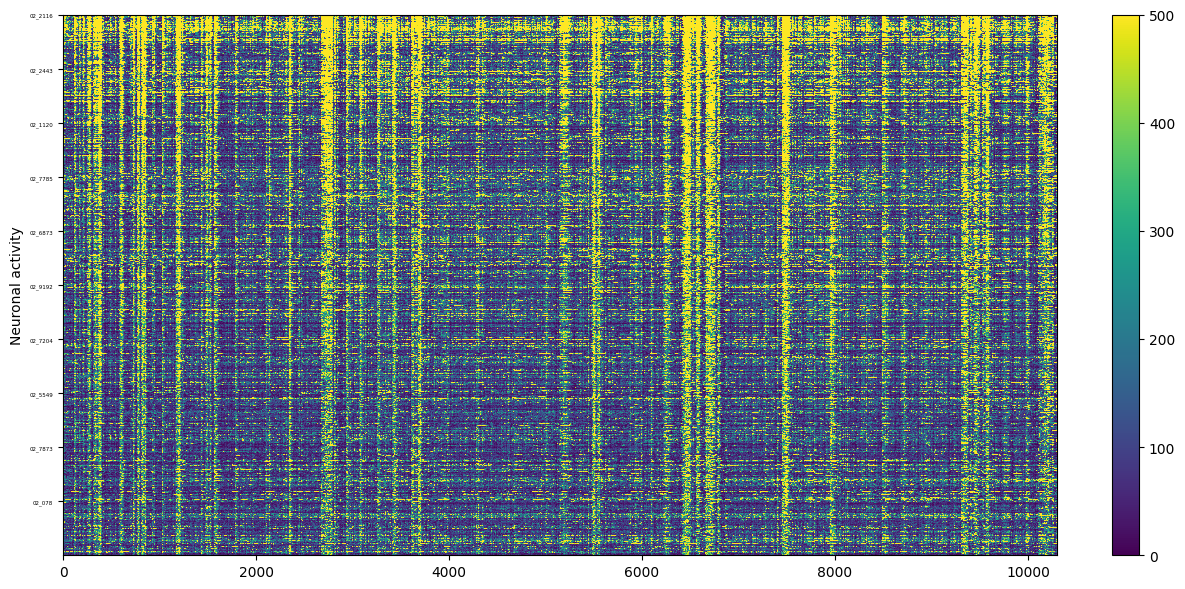

In [13]:
plot_utils.plot_heatmap_stack(traces[plot_idx].iloc[:, traces_manifolds_indices[plot_idx]].iloc[:, :1000],
							  None,
							  label_traces='Neuronal activity', label_behavior=None,
							  height_ratios=(0, 1),
							  zlimits_activity=(0, 500), cmap='viridis')

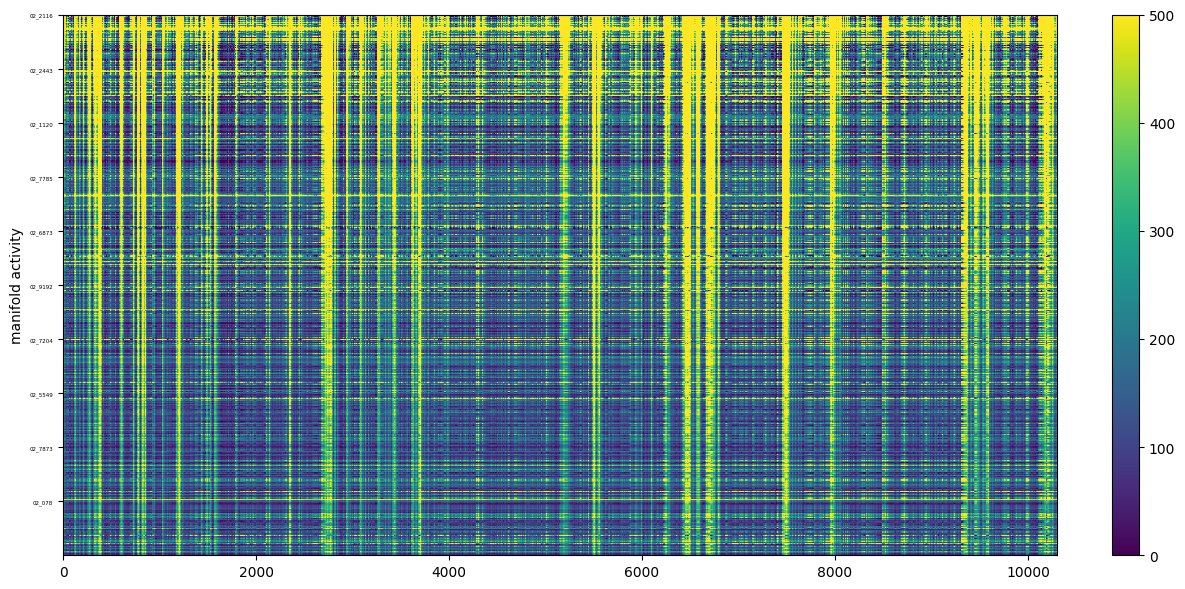

In [16]:
plot_utils.plot_heatmap_stack(recos_manifold[plot_idx].iloc[:, traces_manifolds_indices[plot_idx]].iloc[:, :1000],
							  None,
							  label_traces='manifold activity', label_behavior=None,
							  height_ratios=(0, 1),
							  zlimits_activity=(0, 500), cmap='viridis')

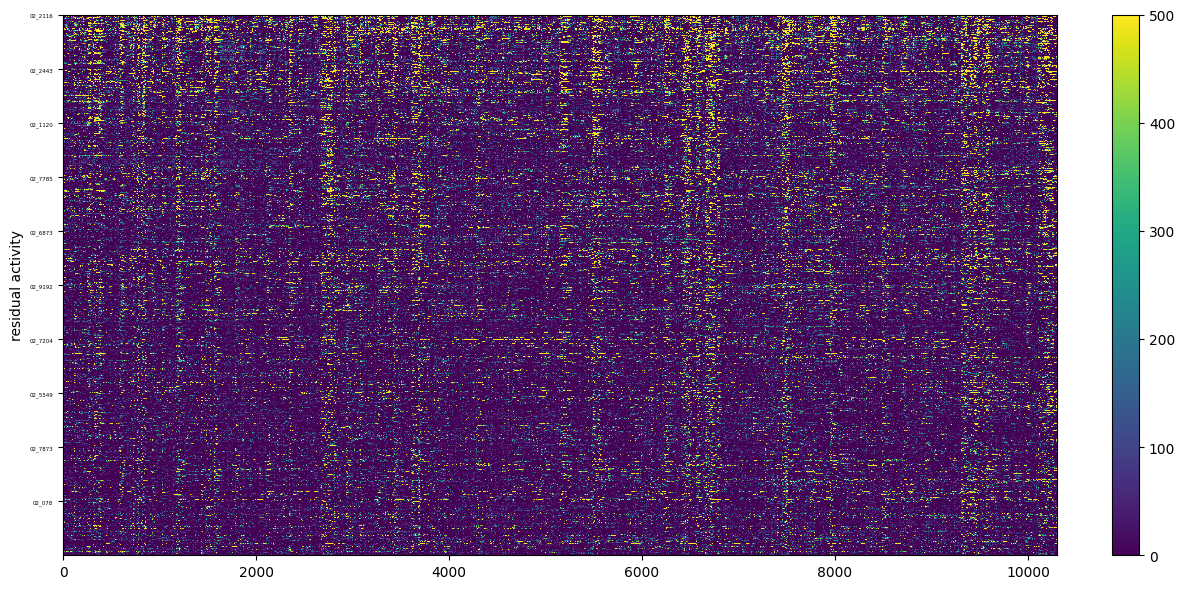

In [17]:
plot_utils.plot_heatmap_stack(traces_residuals[plot_idx].iloc[:, traces_manifolds_indices[plot_idx]].iloc[:, :1000],
							  None,
							  label_traces='residual activity', label_behavior=None,
							  height_ratios=(0, 1),
							  zlimits_activity=(0, 500), cmap='viridis')